# Assignment 3: DQN for HP Protein Folding

Two DQN agents are trained with Stable-Baselines3 to fold HP protein sequences on a 2D lattice. The main agent uses a fully connected network on the environment's grid observation. As an extra, a second agent uses an LSTM that reads the chain one residue at a time (Yang et al., 2023). Both agents are trained on random sequences and tested on proteins they have never seen.

## 1. Environment & Experimental Design

The environment is the project's custom Gymnasium version of gym-lattice (Miranda, 2018). A protein is a string of H (Hydrophobic) and P (Polar) residues that is placed on a square grid one residue at a time. Each step the agent picks one of 4 moves (left, down, up or right) for the next residue. A move onto a cell that is already taken is a collision: nothing is placed and the step costs -2. An episode ends when every residue is placed or when the chain gets stuck with no free cell next to it (trapped, -floor(N/2)). The final step gives the number of H-H contacts (two H residues next to each other on the grid that are not bonded) and every step also costs 0.01 times the distance of the chain end from the start. The energy of a fold is -(H-H contacts) so a lower energy is better.

Every episode folds a new random sequence of length 20 so one model learns to fold any 20-residue protein.

| Parameter | Setting |
|---|---|
| Algorithm | DQN from Stable-Baselines3 |
| Agents | FC Reads the Flattened Grid Observation and LSTM Reads the Sequence View |
| FC Network | CustomANN 5058-256-84 (ReLU) + Linear Q-Value Output for the 4 Moves |
| LSTM Network | CustomLSTM: 2-Layer LSTM with 256 Units over 20 Rows of 7 Columns, Last Output + 4 Free-Move Flags (260 Features) + Linear Q-Value Output for the 4 Moves |
| DQN Hyperparameters | Learning Rate 0.0005; Batch Size 32; Gamma 0.98; Replay Buffer 10,000 (20,000 for the 200K Runs); Learning Starts 1,000 Steps; 10 Gradient Steps After Every Episode; Target Network Copied Every 1,900 Steps (About 100 Episodes) |
| Exploration | Epsilon = 0.01 + 0.99 x exp(-5 x Episode / Total Episodes) Decayed Once per Episode |
| Training | 100,000 Episodes of Random 20-Residue Sequences per Run (FC 100K and LSTM 100K) and a Second Round with 200,000 Episodes (FC 200K and LSTM 200K) |
| Seeds | 7, 14 and 21 for Each Agent |
| Validation | 50 Random Proteins (Seed 1000) Folded Greedily Every 1,000 Episodes; the Best Score Is Saved as best_model |
| Test | 100 Random Proteins (Seed 2000) Plus the 20mer-A and 20mer-B Benchmarks |
| Score | Average H-H Contacts of the Greedy Folds with Folds That Don't Finish Counted as 0 |
| Baselines | Random Moves on the Same Proteins: One Try and the Best of 100 Tries |

## 2. Dependencies, Imports & Configuration

In [1]:
# Install only missing dependencies in the notebook kernel
import importlib.util

required_modules = ["gymnasium", "stable_baselines3", "torch", "numpy", "pandas", "matplotlib", "gym_lattice"]

if any(importlib.util.find_spec(module) is None for module in required_modules):
    %pip install -q -r requirements.txt pandas matplotlib
else:
    print("Required packages OK!")

Required packages OK!


In [2]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from stable_baselines3 import DQN

from dqn.envs import count_contacts, moves_to_coords
from dqn.train import seeds, log_root
from dqn.evaluate import (get_test_sequences, evaluate_model, random_baseline, results_table, show_fold, watch_agent)

# Hide the env's "agent was trapped" warning
gym.logger.min_level = gym.logger.ERROR

In [ ]:
# Make folder per agent and seed
run_dirs = {
    "fc": [os.path.join(log_root, "20mer", "fc_fixed", "seed" + str(seed)) for seed in seeds],
    "lstm": [os.path.join(log_root, "20mer", "lstm", "seed" + str(seed)) for seed in seeds],
}

# The same two agents above but trained for 200K episodes instead of 100K
long_dirs = {
    "fc": [os.path.join(log_root, "20mer", "fc_long_fixed", "seed" + str(seed)) for seed in seeds],
    "lstm": [os.path.join(log_root, "20mer", "lstm_long", "seed" + str(seed)) for seed in seeds],
}

run_groups = [(" 100K", run_dirs), (" 200K", long_dirs)]

test_seqs = get_test_sequences()
for name, seq in test_seqs.items():
    print(name, seq)

## 3. Training

In [4]:
%load_ext tensorboard
%tensorboard --logdir_spec fc_100k:logs/dqn/20mer/fc_fixed,fc_200k:logs/dqn/20mer/fc_long_fixed,lstm_100k:logs/dqn/20mer/lstm,lstm_200k:logs/dqn/20mer/lstm_long

In [5]:
# One row per run from the settings each run saved
import json

rows = []
for kind, groups in run_groups:
    for net, dirs in groups.items():
        for run_dir in dirs:
            with open(os.path.join(run_dir, "design_settings.json")) as f:
                design = json.load(f)
            rows.append({
                "Run": net.upper() + kind,
                "Seed": design["seed"],
                "Episodes": design["num_episodes"],
                "Timesteps": design.get("timesteps"),
                "Training Minutes": design.get("training_minutes"),
                "Q-Network Parameters": design["q_network_parameters"],
            })
pd.DataFrame(rows)

,Run,Seed,Episodes,Timesteps,Training Minutes,Q-Network Parameters
0,FC 100K,7,100000,2071341,491.4,1317032
1,FC 100K,14,100000,2068190,488.8,1317032
2,FC 100K,21,100000,2066703,487.8,1317032
3,LSTM 100K,7,100000,2050441,449.7,798740
4,LSTM 100K,14,100000,2050794,449.7,798740
5,LSTM 100K,21,100000,2049020,449.4,798740
6,FC 200K,7,200000,4137528,904.5,1317032
7,FC 200K,14,200000,4112815,900.9,1317032
8,FC 200K,21,200000,4133168,902.3,1317032
9,LSTM 200K,7,200000,4099332,760.5,798740


In [6]:
# Best validation score of each run and when it happened best_model.zip based on that
rows = []
for kind, groups in run_groups:
    for net, dirs in groups.items():
        for run_dir in dirs:
            history = pd.read_csv(os.path.join(run_dir, "eval_history.csv"))
            best = history.loc[history["score"].idxmax()]
            rows.append({
                "Run": net.upper() + kind,
                "Seed": int(os.path.basename(run_dir)[4:]),
                "Best Score": best["score"],
                "At Episode": int(best["episodes"]),
                "Latest Score": history["score"].iloc[-1],
                "Latest Episode": int(history["episodes"].iloc[-1]),
            })
pd.DataFrame(rows)

,Run,Seed,Best Score,At Episode,Latest Score,Latest Episode
0,FC 100K,7,3.12,46000,3.10,100000
1,FC 100K,14,3.14,48000,2.14,100000
2,FC 100K,21,3.36,40000,3.26,100000
3,LSTM 100K,7,5.54,75000,5.40,100000
4,LSTM 100K,14,5.50,69000,5.40,100000
5,LSTM 100K,21,5.50,80000,5.46,100000
6,FC 200K,7,3.20,163000,2.50,200000
7,FC 200K,14,2.94,198000,2.64,200000
8,FC 200K,21,3.30,137000,2.74,200000
9,LSTM 200K,7,5.04,154000,4.80,200000


## 4. Results

Test Contacts is the average number of H-H contacts on the 100 random test proteins with folds that don't finish counted as 0. The benchmark columns are energies so lower is better.

In [ ]:
# Fold every test protein with each run's best model, final model and 1M-step checkpoint
model_files = {"best_model": "Best", "final_model": "Final", "checkpoints/model_1000000": "1M Steps"}

evaluations = {}
model_paths = {}
for kind, groups in run_groups:
    for net, dirs in groups.items():
        for run_dir in dirs:
            seed = int(os.path.basename(run_dir)[4:])
            for file_name, model_label in model_files.items():
                path = os.path.join(run_dir, file_name + ".zip")
                # Skip models that a run hasn't saved yet
                if not os.path.exists(path):
                    continue
                model = DQN.load(path, device="cpu")
                label = net.upper() + kind + " Seed " + str(seed) + " (" + model_label + ")"
                evaluations[label] = evaluate_model(model, net, test_seqs)
                model_paths[label] = path

# Random moves on the same proteins: one try each and the best of 100 tries
random_one = random_baseline(test_seqs, tries=1, seed=0)
random_best = random_baseline(test_seqs, tries=100, seed=0)
evaluations["Random (1 Try)"] = random_one
evaluations["Random (Best of 100)"] = random_best

# One row per saved model
results = results_table(evaluations)
results

In [8]:
# Mean over the 3 seeds for each agent and saved model
rows = []
for net in ["fc", "lstm"]:
    for kind in [" 100K", " 200K"]:
        for model_label in model_files.values():
            labels = [net.upper() + kind + " Seed " + str(seed) + " (" + model_label + ")" for seed in seeds]
            runs = results[results["Model"].isin(labels)]
            if len(runs) == 0:
                continue
            rows.append({
                "Agent": net.upper() + kind + " (" + model_label + ")",
                "Test Contacts": runs["Test Contacts"].mean(),
                "Std over Seeds": runs["Test Contacts"].std(),
                "Best 20mer-A": runs["20mer-A"].min(),
                "Best 20mer-B": runs["20mer-B"].min(),
            })
summary = pd.DataFrame(rows)

# The random baselines and the best known energies to compare with
for name in ["Random (1 Try)", "Random (Best of 100)", "Best Known"]:
    row = results[results["Model"] == name].iloc[0]
    rows.append({"Agent": name, "Test Contacts": row["Test Contacts"],
                 "Best 20mer-A": row["20mer-A"], "Best 20mer-B": row["20mer-B"]})
table = pd.DataFrame(rows).round(2)
# Whole numbers for the energies
table[["Best 20mer-A", "Best 20mer-B"]] = table[["Best 20mer-A", "Best 20mer-B"]].astype("Int64")
table

,Agent,Test Contacts,Std over Seeds,Best 20mer-A,Best 20mer-B
0,FC 100K (Best),3.12,0.15,-4,-4
1,FC 100K (Final),2.97,0.45,-4,-6
2,FC 100K (1M Steps),2.23,0.18,-2,-4
3,FC 200K (Best),3.05,0.21,-5,-3
4,FC 200K (Final),2.90,0.20,-4,-5
5,FC 200K (1M Steps),2.00,0.26,-3,-2
6,LSTM 100K (Best),5.57,0.02,-6,-7
7,LSTM 100K (Final),5.67,0.04,-7,-7
8,LSTM 100K (1M Steps),5.40,0.08,-6,-7
9,LSTM 200K (Best),5.42,0.51,-6,-7


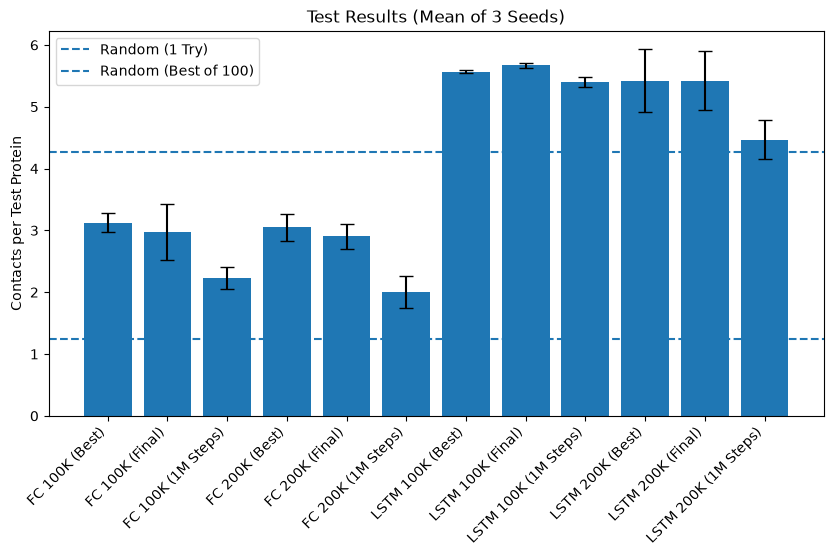

In [9]:
# Average contacts on the test proteins with error bars of one standard deviation over the seeds
plt.figure(figsize=(10, 5))
plt.bar(summary["Agent"], summary["Test Contacts"], yerr=summary["Std over Seeds"], capsize=5)
for label, baseline in [("Random (1 Try)", random_one), ("Random (Best of 100)", random_best)]:
    test_contacts = baseline[baseline["name"].str.startswith("test")]["contacts"].mean()
    plt.axhline(test_contacts, linestyle="--", label=label)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Contacts per Test Protein")
plt.title("Test Results (Mean of 3 Seeds)")
plt.legend()
plt.show()

## 5. Demo

Each agent folds a protein one move at a time. `demo_seq` can be any 20 letters of H and P.

In [10]:
# Each agent folds the protein with its model that scored best on the test proteins
demo_seq = test_seqs["20mer-A"]
for net in ["FC", "LSTM"]:
    agent_results = results[results["Model"].str.startswith(net + " ")]
    label = agent_results.loc[agent_results["Test Contacts"].idxmax(), "Model"]
    print(label)
    watch_agent(DQN.load(model_paths[label], device="cpu"), net.lower(), demo_seq)

FC 200K Seed 21 (Best)

***
*H*
***
  (Right)
****
*HP*
****
  (Up)
****
**H*
*HP*
****
  (Up)
****
**P*
**H*
*HP*
****
  (Left)
****
*PP*
**H*
*HP*
****
  (Down)
****
*PP*
*HH*
*HP*
****
  (Left)
*****
**PP*
*HHH*
**HP*
*****
  (Down)
*****
**PP*
*HHH*
*PHP*
*****
  (Down)
*****
**PP*
*HHH*
*PHP*
*H***
*****
  (Right)
*****
**PP*
*HHH*
*PHP*
*HP**
*****
  (Right)
*****
**PP*
*HHH*
*PHP*
*HPP*
*****
  (Down)
*****
**PP*
*HHH*
*PHP*
*HPP*
***H*
*****
  (Left)
*****
**PP*
*HHH*
*PHP*
*HPP*
**PH*
*****
  (Left)
*****
**PP*
*HHH*
*PHP*
*HPP*
*HPH*
*****
  (Left)
******
***PP*
**HHH*
**PHP*
**HPP*
*HHPH*
******
  (Up)
******
***PP*
**HHH*
**PHP*
*PHPP*
*HHPH*
******
  (Up)
******
***PP*
**HHH*
*PPHP*
*PHPP*
*HHPH*
******
  (Up)
******
***PP*
*HHHH*
*PPHP*
*PHPP*
*HHPH*
******
  (Up)
******
*P*PP*
*HHHH*
*PPHP*
*PHPP*
*HHPH*
******
  (Right)
******
*PHPP*
*HHHH*
*PPHP*
*PHPP*
*HHPH*
******
Complete: True | Contacts: 5 | Collisions: 0 | Moves: RUULDLDDRRDLLLUUUUR
LSTM 200K Seed 21 (Final)

**

20mer-A Best Known Fold: 9 Contacts
  (Left)
*******
*PHP***
*PHHHP*
*PHHHH*
*HHPPP*
*PP****
*******


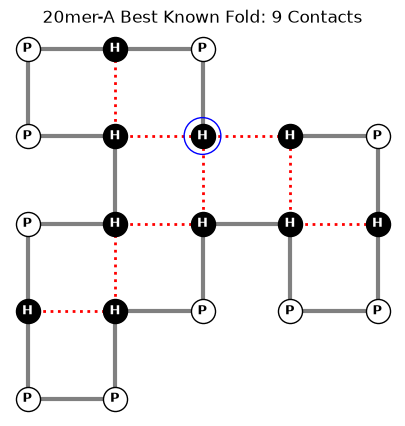

20mer-B Best Known Fold: 10 Contacts
  (Right)
*******
*PHP***
*PHHP**
*PHHHP*
*PHHHP*
**PHP**
*******


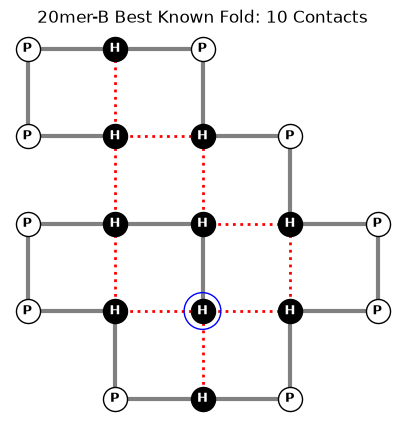

In [11]:
# The best known folds (Yang et al., 2023) to compare with
best_known_folds = {"20mer-A": "ULLDRDLDDRURURDRUUL", "20mer-B": "ULLDRDRRURULULULLDR"}
for name, fold in best_known_folds.items():
    contacts = count_contacts(moves_to_coords(fold), test_seqs[name])
    show_fold(fold, test_seqs[name], name + " Best Known Fold: " + str(contacts) + " Contacts")